# Inflation and Monthly S&P 500 Returns
## INFO 2950 Phase 3 | January 2017-September 2026
**Jaemin Kwon (jk2975) and Mike Zhang (hz727)**  
Neither group member is a native English speaker.

### 1. Introduction
We examine how U.S. inflation relates to monthly S&P 500 price returns. Higher inflation can coincide with rising borrowing costs and pressure on firms' profits, but it can also accompany strong demand. The historical relationship matters because investors may read a negative association as a signal about future returns.

**Research question.** From January 2017 through September 2026, did higher year-over-year headline CPI inflation coincide with lower monthly S&P 500 price returns? Does the association also appear when we use inflation from the previous calendar month? We also ask whether core inflation shows a similar pattern and how consumers' inflation expectations compare with recent inflation.

Fama and Schwert (1977) found a negative relationship between expected inflation and common-stock returns in their 1953-1971 sample. Their distinction between expected and unexpected inflation matters here because we use observed CPI. Bernanke and Kuttner (2004) make a related distinction between anticipated and unexpected monetary policy changes when studying stock prices.

Both models show a weak negative association and explain little of the variation in monthly returns. Evidence for negative slopes depends on how we estimate uncertainty. Core inflation shows a similarly weak relationship with returns, and consumer expectations tend to move with recent headline inflation.

<div class="page-break"></div>

## 2. Data description and cleaning
### Sources and purpose
We assembled a monthly dataset to compare U.S. inflation and stock price returns over the same period. We use four saved Phase 2 series and add FEDFUNDS for the exploratory interest-rate model. FRED distributes all five series.

| Series | Producer and original purpose | Measure used here |
|---|---|---|
| SP500 | S&P Dow Jones Indices, tracking large U.S. companies | Daily close, converted to monthly price return |
| CPIAUCNS | Bureau of Labor Statistics, tracking consumer prices | Headline CPI-U, not seasonally adjusted |
| CPILFENS | Bureau of Labor Statistics, tracking prices excluding food and energy | Core CPI-U, not seasonally adjusted |
| MICH | University of Michigan Surveys of Consumers, surveying consumer expectations | Median expected price change over the next 12 months (%) |
| FEDFUNDS | Board of Governors of the Federal Reserve System, reporting money-market rates | Monthly-average effective federal funds rate (%) |

The four original CSV snapshots are retained rather than refreshed, so Phase 3 uses the same data as Phase 2. FEDFUNDS was downloaded for this phase and restricted to the same study window. Original series definitions are available from FRED (S&P Dow Jones Indices, n.d.; BLS, n.d.-a, n.d.-b; University of Michigan, n.d.; Board of Governors, n.d.).

### What one row and each column represent
Each row represents **one calendar month**. The main file has 116 rows and 13 columns. The lag file adds `previous_headline_yoy_pct` and contains 114 rows.

| Columns | Meaning and units |
|---|---|
| `month_index`, `Year`, `Month`, `date` | Calendar identifiers and a sequential month key |
| `last_trading_date` | Date of the month's final available trading close |
| `sp500_close` | Closing price-index level, in index points |
| `sp500_return_pct` | Change from the previous month-end close, in percent |
| `headline_cpi`, `core_cpi` | CPI index levels; 1982-1984 = 100 |
| `headline_yoy_pct`, `core_yoy_pct` | Change from the same month one year earlier, in percent |
| `expected_inflation_pct` | Consumers' median expected price change over the next year, in percent |
| `fedfunds_pct` | Monthly-average effective federal funds rate, in percent |

A one-unit difference in any rate means **one percentage point**. Returns cover one month, while year-over-year inflation covers twelve months.

<div class="page-break"></div>

### Cleaning and monthly alignment
The [cleaning notebook](https://github.com/jkwon128/INFO2950-Project/blob/phase3-draft-2026-11-05/phase3/Phase3_Data_Cleaning.ipynb) documents the steps and exports the [processed data](https://github.com/jkwon128/INFO2950-Project/tree/phase3-draft-2026-11-05/phase3/data/processed) from the [archived raw data](https://github.com/jkwon128/INFO2950-Project/tree/phase3-draft-2026-11-05/phase3/data/raw).

We drop 96 daily records without an S&P 500 close and select the final available trading close in each month. Monthly price return is the percent change from the previous calendar month's close. Headline and core inflation are the percent changes from their CPI levels twelve calendar months earlier. We join the series by calendar month and leave missing values unfilled.

| Sample | Months | Coverage |
|---|---:|---|
| Study window | 117 | January 2017 through September 2026 |
| Same-month model | 116 | Excludes October 2025, when CPI is missing |
| Previous-month model | 114 | Also excludes January 2017 and November 2025 |
| Expectations comparison | 115 | The snapshot ends in August 2026 |
| Interest-rate extension | 116 | FEDFUNDS covers the full same-month sample |

The Phase 2 plan matches each return to the prior calendar month within the main sample. December 2016 CPI is in the raw data but outside that sample, so January 2017 has no lagged value. November 2025 lacks a lagged value because October 2025 CPI is missing.

### Reliability, collection, and people represented
BLS samples prices to construct an index for urban consumers. A household's own spending may differ from that basket (BLS, n.d.-c). The S&P 500 covers large U.S. public companies, and its price index excludes dividends. The Michigan survey median summarizes consumers' expectations and can hide differences among respondents. We use published aggregates throughout.

BLS (2025) attributes the October 2025 CPI gap to the federal government shutdown. That gap leaves the association for the omitted months unknown. Keeping archived snapshots makes the data inputs traceable if FRED later revises the series or changes their coverage. Our description follows Gebru et al. (2021).

<div class="page-break"></div>

## 3. Preregistration statements
### Statement 1: Same-month headline inflation and returns
**Hypothesis:** Higher year-over-year headline inflation is associated with lower same-month S&P 500 price returns.

**Planned analysis:** Fit a simple linear regression with an intercept using all 116 eligible months. The predictor is `headline_yoy_pct`; the outcome is `sp500_return_pct`. Report the sample size, intercept, slope, R², and a scatterplot with the fitted line. The slope measures percentage points of monthly return per percentage point of inflation.

Higher inflation could coincide with higher costs or expected policy tightening, motivating the negative direction. Fama and Schwert (1977) provide historical context, although their measures and period differ from ours. Stronger demand could work in the opposite direction, so the hypothesis is a possibility to investigate rather than a rule we assume.

### Statement 2: Previous-month headline inflation and returns
**Hypothesis:** Higher year-over-year headline inflation in the previous calendar month is associated with lower S&P 500 price returns in the current month.

**Planned analysis:** Fit the same type of regression using `previous_headline_yoy_pct` and the planned 114-month sample. The predictor is matched by calendar month. Report the same quantities as in Statement 1. This asks whether the association also appears when inflation is measured one month earlier.

The two analyses are closely related, as our reviewers noted. They are not independent replications or a formal comparison of timing effects. CPI for the previous month is generally released during the current return month (BLS, n.d.-d). Therefore, even the lagged model does not reproduce information available at the beginning of that month.

### What was added for Phase 3
The final Phase 2 submission specifies previous-month headline inflation for Statement 2, superseding an earlier plan that used core inflation. Core inflation and expectations remain descriptive. Phase 2 exploratory analysis already revealed the same-month slope direction and R².

Phase 3 adds one-sided tests of **H₀: slope ≥ 0** against **Hₐ: slope < 0** at the zero boundary. The primary tests use calendar-aware HAC standard errors with three monthly lags and Holm correction across the two tests at a family-wise 5% level. We also report two-sided 95% intervals, six- and twelve-lag checks, and ordinary OLS uncertainty for comparison.

We report both planned models alongside three exploratory comparisons: excluding March and April 2020, fitting both models on the same months, and adding the federal funds rate. The [analysis amendment](support/analysis_amendment.md) records these Phase 3 additions. The draft already contained fitted results at review, and the timing of the amendment relative to the first fit could not be verified.

<div class="page-break"></div>

## 4. Data analysis
### Load the cleaned data
The report starts with the files exported by the separate cleaning notebook. We check the expected sample sizes and required fields before fitting the models.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

DATA = Path("data/processed")
names = ["main", "lag", "same_common", "main_no_extremes",
         "lag_no_extremes", "expectations", "interest"]
samples = {name: pd.read_csv(DATA / f"{name}.csv", parse_dates=["date"])
           for name in names}
main, lagged = samples["main"], samples["lag"]
assert len(main) == 116 and len(lagged) == 114
for frame in samples.values():
    assert not frame.month_index.duplicated().any()
    assert frame[["sp500_return_pct", "headline_yoy_pct"]].notna().all().all()
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
print("Loaded seven prepared samples; main n=116, lagged n=114.")

Loaded seven prepared samples; main n=116, lagged n=114.


### Typical values and spread
Table 1 puts the slopes into context. All four variables below are percentages, but the stock return covers one month and the inflation measures cover a year.

In [2]:
variables = ["sp500_return_pct", "headline_yoy_pct",
             "core_yoy_pct", "expected_inflation_pct"]
summary = main[variables].agg(["count", "mean", "std", "min", "max"]).T
summary.index = ["Monthly return", "Headline inflation",
                 "Core inflation", "Expected inflation"]
display(summary.round(3))

,count,mean,std,min,max
Monthly return,116.0000,1.1460,4.4910,-12.5120,12.6840
Headline inflation,116.0000,3.3510,2.0400,0.1180,9.0600
Core inflation,116.0000,3.1500,1.4680,1.1870,6.6310
Expected inflation,115.0000,3.5280,1.0250,2.1000,6.6000


**Table 1.** Returns average 1.146%, with a standard deviation of 4.491 percentage points. They range from -12.512% to 12.684%, so there is substantial variation to explain. Headline inflation averages 3.351% and ranges from 0.118% to 9.060%. Expectations use 115 observations; the other summaries use 116.

<div class="page-break"></div>

### The time pattern behind the models
Figure 1 shows why it is useful to look at dates before interpreting a fitted line. The upper panel follows inflation conditions; the lower panel shows the return outcome on its own scale. October 2025 is left as a gap.

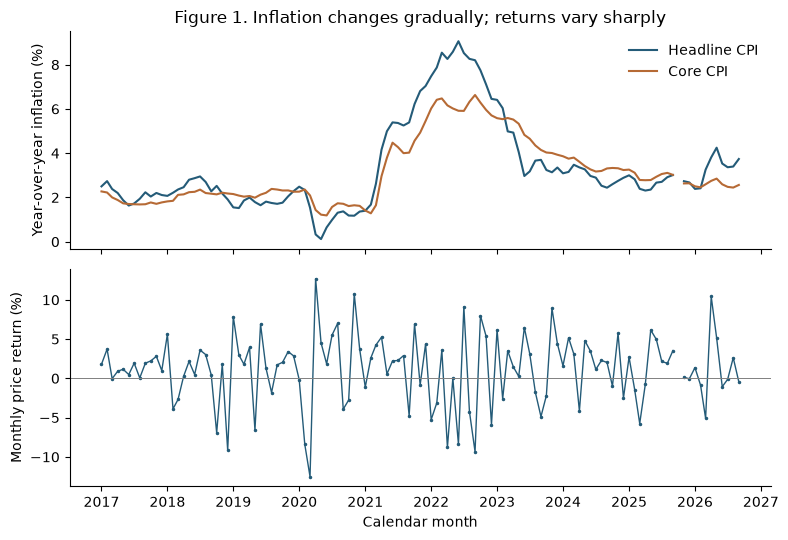

In [3]:
# Reindex only the plotted series so lines do not bridge the missing month.
dates = pd.date_range("2017-01-01", "2026-09-01", freq="MS")
plot_data = main.set_index("date").reindex(dates)
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
for column, label, color in [
    ("headline_yoy_pct", "Headline CPI", "#245b78"),
    ("core_yoy_pct", "Core CPI", "#b66a35")]:
    axes[0].plot(plot_data.index, plot_data[column], label=label, color=color)
axes[0].set_ylabel("Year-over-year inflation (%)")
axes[0].legend(frameon=False)
axes[0].set_title("Figure 1. Inflation changes gradually; returns vary sharply")
axes[1].plot(plot_data.index, plot_data.sp500_return_pct,
             color="#245b78", linewidth=1, marker=".", markersize=3)
axes[1].axhline(0, color="gray", linewidth=0.7)
axes[1].set_ylabel("Monthly price return (%)")
axes[1].set_xlabel("Calendar month")
plt.tight_layout()
plt.show()

The largest return loss and gain occur in consecutive months: March and April 2020. Headline inflation rises later to its sample peak in June 2022. These different patterns suggest that the return models may leave a large amount unexplained. The 2020 observations are genuine events, so they remain in the main analyses. The separate sensitivity check asks how much the fitted slopes change without them.

<div class="page-break"></div>

### Analysis 1: Same-month inflation
We first fit the regression specified in Statement 1. `LinearRegression` includes an intercept by default. The fitted line minimizes the sum of squared differences between observed and fitted monthly returns.

n = 116
Return = 2.316 -0.349 × inflation
R-squared = 0.0252
In-sample RMSE = 4.415 percentage points


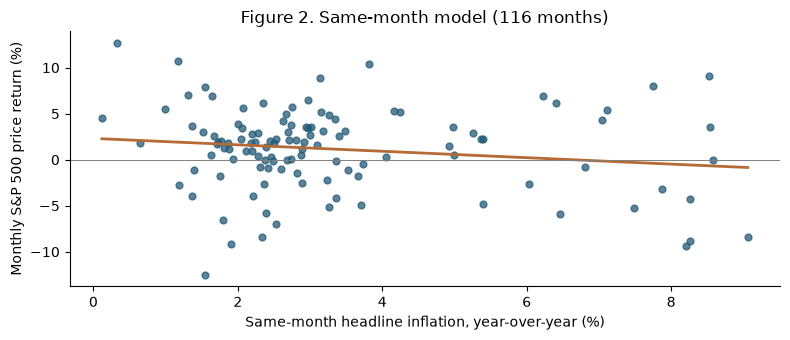

In [4]:
x1 = "headline_yoy_pct"
y = "sp500_return_pct"
model1 = LinearRegression().fit(main[[x1]], main[y])
fitted1 = model1.predict(main[[x1]])
residual1 = main[y].to_numpy() - fitted1
print(f"n = {len(main)}")
print(f"Return = {model1.intercept_:.3f} {model1.coef_[0]:+.3f} × inflation")
print(f"R-squared = {model1.score(main[[x1]], main[y]):.4f}")
print(f"In-sample RMSE = {np.sqrt(np.mean(residual1**2)):.3f} percentage points")

fig, ax = plt.subplots()
ax.scatter(main[x1], main[y], s=24, alpha=0.75, color="#245b78")
grid = pd.DataFrame({x1: np.linspace(main[x1].min(), main[x1].max(), 100)})
ax.plot(grid[x1], model1.predict(grid), color="#b66a35", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Same-month headline inflation, year-over-year (%)",
       ylabel="Monthly S&P 500 price return (%)",
       title="Figure 2. Same-month model (116 months)")
plt.tight_layout()
plt.show()

**Summarizing.** A one percentage point higher inflation rate is associated with about **0.349 percentage points lower monthly return**. The sign agrees with the hypothesis, but R² = 0.0252 means the line explains only about 2.5% of observed return variation. Figure 2 shows a wide spread of gains and losses around the line. The intercept is 2.316%, the fitted return at zero inflation, slightly below the observed range.

<div class="page-break"></div>

### Analysis 2: Previous-month inflation
The second regression uses the previous calendar month's inflation. Its 114 rows follow the original sample rule; the lag was prepared in the cleaning notebook and is not a row-wise shift across the missing month.

n = 114
Return = 2.387 -0.369 × prior inflation
R-squared = 0.0282
In-sample RMSE = 4.445 percentage points


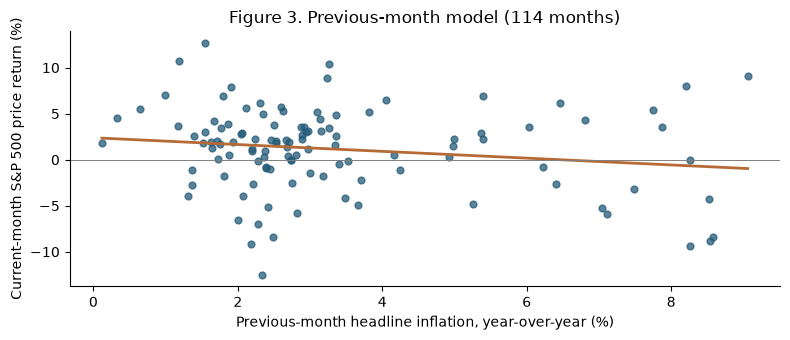

In [5]:
x2 = "previous_headline_yoy_pct"
model2 = LinearRegression().fit(lagged[[x2]], lagged[y])
fitted2 = model2.predict(lagged[[x2]])
residual2 = lagged[y].to_numpy() - fitted2
print(f"n = {len(lagged)}")
print(f"Return = {model2.intercept_:.3f} {model2.coef_[0]:+.3f} × prior inflation")
print(f"R-squared = {model2.score(lagged[[x2]], lagged[y]):.4f}")
print(f"In-sample RMSE = {np.sqrt(np.mean(residual2**2)):.3f} percentage points")

fig, ax = plt.subplots()
ax.scatter(lagged[x2], lagged[y], s=24, alpha=0.75, color="#245b78")
grid = pd.DataFrame({x2: np.linspace(lagged[x2].min(), lagged[x2].max(), 100)})
ax.plot(grid[x2], model2.predict(grid), color="#b66a35", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Previous-month headline inflation, year-over-year (%)",
       ylabel="Current-month S&P 500 price return (%)",
       title="Figure 3. Previous-month model (114 months)")
plt.tight_layout()
plt.show()

**Summarizing.** A one percentage point higher previous-month inflation rate is associated with about **0.369 percentage points lower current-month return**. R² is 0.0282, or about 2.8%. This is close to the first model, which is expected because inflation usually changes gradually between neighboring months. The two R² values describe fits on slightly different sets of months.

<div class="page-break"></div>

### Predicting and examining unusual observations
To make the slopes concrete, Table 2 evaluates both fitted lines at 2% and 6% inflation. Both values lie within the data range. The values describe the fitted average return at each inflation rate.

In [6]:
prediction_rows = []
for label, model, x in [("Same month", model1, x1),
                         ("Previous month", model2, x2)]:
    values = model.predict(pd.DataFrame({x: [2.0, 6.0]}))
    prediction_rows.append({"Model": label, "At 2% inflation": values[0],
                            "At 6% inflation": values[1],
                            "Difference (6% - 2%)": values[1] - values[0]})
display(pd.DataFrame(prediction_rows).set_index("Model").round(3))

,At 2% inflation,At 6% inflation,Difference (6% - 2%)
Model,,,
Same month,1.6180,0.2210,-1.3970
Previous month,1.6480,0.1700,-1.4780


**Table 2.** The same-month fitted return falls from 1.618% to 0.221%, a difference of about 1.397 percentage points. The lagged fitted return falls from 1.648% to 0.170%. These differences are much smaller than the models' residual RMSEs of about 4.4 percentage points. An individual month's return can therefore be far from its fitted value. Forecast accuracy would require testing on held-out months.

**Outliers and oddities.** A large return is not automatically the most influential observation: an unusual inflation value can also pull the line. We use Cook's distance to identify months that have a larger influence on the first fitted regression, without deleting them.

In [7]:
ols1 = sm.OLS(main[y], sm.add_constant(main[[x1]])).fit()
ols2 = sm.OLS(lagged[y], sm.add_constant(lagged[[x2]])).fit()
influence = main[["date", x1, y]].copy()
influence["Residual (pp)"] = residual1
influence["Cook distance"] = ols1.get_influence().cooks_distance[0]
top_influence = influence.nlargest(3, "Cook distance").copy()
top_influence["date"] = top_influence["date"].dt.strftime("%Y-%m")
display(top_influence.round(3))
assert np.allclose(ols1.params, [model1.intercept_, model1.coef_[0]])
assert np.allclose(ols2.params, [model2.intercept_, model2.coef_[0]])

,date,headline_yoy_pct,sp500_return_pct,Residual (pp),Cook distance
66,2022-07,8.5250,9.1120,9.7730,0.1780
65,2022-06,9.0600,-8.3920,-7.5440,0.1290
68,2022-09,8.2020,-9.3400,-8.7910,0.1270


**Table 3.** July, June, and September 2022 have the largest Cook's distances in the same-month model. These months combine high inflation with large positive or negative returns. The largest absolute returns in 2020 are therefore not the only observations worth examining. Cook's distance is a diagnostic, not a rule for discarding real observations. We retain them and use the separately specified March-April 2020 comparison below. Agreement between the scikit-learn and statsmodels coefficients also confirms that both implementations fit the same intercept model.

<div class="page-break"></div>

### Residual checks for both return models
The reviewers asked us to examine time dependence before making significance claims. Figure 4 checks both return regressions directly. The upper panels compare residuals with fitted returns; the lower panels keep calendar order and show gaps where a model has no observation.

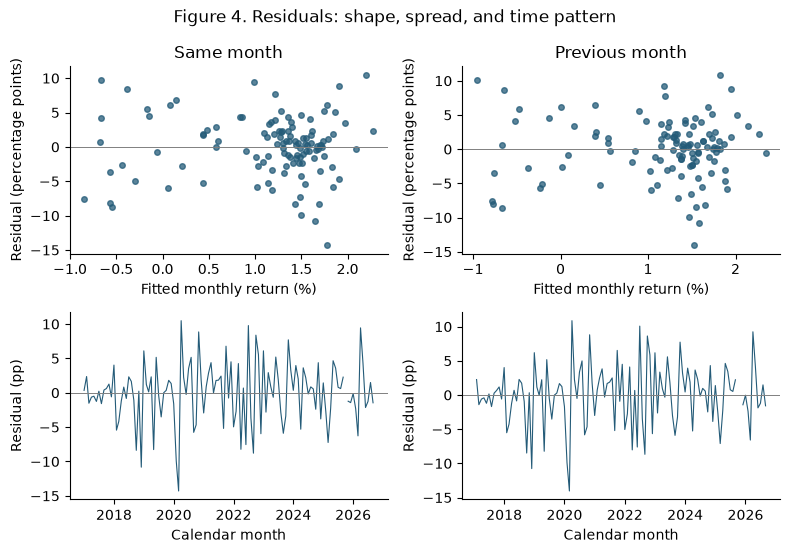

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(8, 5.6))
diagnostic_models = [("Same month", main, fitted1, residual1),
                     ("Previous month", lagged, fitted2, residual2)]
for j, (label, frame, fitted, residual) in enumerate(diagnostic_models):
    axes[0, j].scatter(fitted, residual, s=16, alpha=0.75, color="#245b78")
    axes[0, j].set(title=label, xlabel="Fitted monthly return (%)",
                   ylabel="Residual (percentage points)")
    r = pd.Series(residual, index=frame.date).reindex(dates)
    axes[1, j].plot(r.index, r, linewidth=0.8, color="#245b78")
    axes[1, j].set(xlabel="Calendar month", ylabel="Residual (pp)")
    axes[1, j].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[1, j].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    for i in range(2):
        axes[i, j].axhline(0, color="gray", linewidth=0.7)
fig.suptitle("Figure 4. Residuals: shape, spread, and time pattern")
plt.tight_layout()
plt.show()

Neither fitted line captures the large swings around the 2020 crash and rebound. The residuals also vary in size across time. There is no obvious smooth curve in the upper panels, but that does not prove that a linear model or constant error variance is correct. The lower panels show why ordinary independent-error uncertainty deserves scrutiny. The next table checks selected calendar lags without treating September and November 2025 as adjacent months.

<div class="page-break"></div>

### Residual correlations at calendar lags
We compare only pairs separated by the stated number of calendar months. Pair counts differ because the samples contain gaps. These correlations are descriptive checks rather than formal tests of independence.

In [9]:
def residual_pairs(frame, residual, lag):
    series = pd.Series(np.asarray(residual), index=frame.month_index)
    earlier = series.copy()
    earlier.index = earlier.index + lag
    pairs = pd.concat([series, earlier], axis=1).dropna()
    return pairs.iloc[:, 0].corr(pairs.iloc[:, 1]), len(pairs)

rows = []
for label, frame, fitted, residual in diagnostic_models:
    for months in [1, 3, 6, 12]:
        correlation, count = residual_pairs(frame, residual, months)
        rows.append({"Model": label, "Lag (months)": months,
                     "Residual correlation": correlation, "Pairs": count})
display(pd.DataFrame(rows).round(3))

,Model,Lag (months),Residual correlation,Pairs
0,Same month,1,-0.1670,114
1,Same month,3,0.0280,112
2,Same month,6,-0.0940,109
3,Same month,12,0.0570,104
4,Previous month,1,-0.1740,112
5,Previous month,3,0.0290,109
6,Previous month,6,-0.0910,106
7,Previous month,12,0.0680,102


**Table 4.** At one month, residual correlations are about -0.167 and -0.174. The other displayed correlations are smaller in absolute value. This suggests modest short-run reversal rather than strong persistence in the mean residual, but the sample is too limited to establish independence. Changing volatility can also matter even when residual correlations are small.

## 5. Evaluation of significance
### Why the uncertainty method matters
Ordinary OLS standard errors assume uncorrelated errors with constant variance. We retain the same fitted coefficients but use **heteroskedasticity and autocorrelation consistent (HAC)** standard errors for the primary inference. This allows the uncertainty estimate to reflect changing error variance and correlation over nearby months.

We use Bartlett weights through **three calendar months**, giving more weight to closer pairs. Three months is the short-run allowance used in the working draft. It is not a claim that dependence ends after a quarter. Six- and twelve-month versions check this choice. Datta and Du (2012) discuss HAC estimation with missing observations. Our implementation keeps missing months in the score sequence with zero contributions; it does not impute returns or CPI. The ordinary statsmodels HAC routine assumes consecutive, equally spaced rows, so we show the calendar-aware calculation explicitly.

The resulting p-values use an approximate normal reference distribution, with a sample-size correction in the covariance. These are model-based approximations, not exact randomization tests. A short sample spanning several economic regimes can still make them unreliable. We report ordinary OLS results as a comparison so that this dependence on method is visible.

### Calculate calendar-aware HAC uncertainty
The function below builds the covariance from each observed month's residual and predictor values. The matrix calculation changes standard errors, not the regression line. Missing months contribute no scores, and actual month differences determine the lag weights.

In [10]:
def calendar_hac(frame, predictors, max_lag=3):
    """OLS covariance with Bartlett weights at actual calendar-month lags."""
    X = np.column_stack([np.ones(len(frame)), frame[predictors].to_numpy()])
    y = frame.sp500_return_pct.to_numpy()
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    residual = y - X @ beta
    scores = X * residual[:, None]
    months = frame.month_index.to_numpy(dtype=int)
    # Zero score contributions preserve gaps; no missing data values are filled.
    grid = np.zeros((months.max() - months.min() + 1, X.shape[1]))
    grid[months - months.min()] = scores
    meat = grid.T @ grid
    for lag in range(1, max_lag + 1):
        weight = 1 - lag / (max_lag + 1)
        cross = grid[lag:].T @ grid[:-lag]
        meat += weight * (cross + cross.T)
    bread = np.linalg.inv(X.T @ X)
    n, k = X.shape
    covariance = n / (n - k) * bread @ meat @ bread
    se = np.sqrt(np.diag(covariance))
    return beta, se, covariance

For each main slope, the test statistic is its estimate divided by its HAC standard error. Because our hypotheses specify a **negative** direction, the p-value is the lower-tail probability under a zero slope. It describes how unusual a statistic this negative or more negative would be under the boundary null and the model assumptions; it is not the probability that the hypothesis is true.

We use Holm's correction because there are two primary tests. It controls the family-wise error rate without requiring the two tests to be independent, provided the underlying p-values are valid. The correction does not remove uncertainty about the HAC approximation or undo the fact that Phase 2 EDA already exposed the first model's direction. The 95% confidence intervals below are individual, two-sided intervals, not simultaneous intervals for both coefficients.

<div class="page-break"></div>

### Main significance results
Table 5 reports the slopes, standard errors, confidence intervals, and one-sided p-values. Table 6 applies the two-test correction and states the decisions.

In [11]:
specs = [("Same month", main, x1), ("Previous month", lagged, x2)]
inference_rows = []
for label, frame, predictor in specs:
    beta, se, covariance = calendar_hac(frame, [predictor], max_lag=3)
    low, high = beta[1] + np.array([-1, 1]) * norm.ppf(0.975) * se[1]
    inference_rows.append({"Model": label, "Slope": beta[1],
        "HAC SE": se[1], "95% lower": low, "95% upper": high,
        "One-sided p": norm.cdf(beta[1] / se[1])})
inference = pd.DataFrame(inference_rows).set_index("Model")
reject, adjusted, _, _ = multipletests(
    inference["One-sided p"], alpha=0.05, method="holm")
display(inference.round(4))
decisions = pd.DataFrame({"Holm-adjusted p": adjusted,
    "Decision": np.where(reject, "Reject H0", "Fail to reject H0")},
    index=inference.index)
display(decisions.round(4))

,Slope,HAC SE,95% lower,95% upper,One-sided p
Model,,,,,
Same month,-0.3493,0.1637,-0.6701,-0.0284,0.0164
Previous month,-0.3694,0.1594,-0.6818,-0.0570,0.0102


,Holm-adjusted p,Decision
Model,,
Same month,0.0205,Reject H0
Previous month,0.0205,Reject H0


**Tables 5-6.** The same-month slope is -0.349, with a 95% interval of about **[-0.670, -0.028]**. The previous-month slope is -0.369, with an interval of about **[-0.682, -0.057]**. Their one-sided p-values are approximately 0.0164 and 0.0102. After Holm correction, both adjusted p-values are approximately **0.0205**.

At the chosen family-wise 5% level, we **reject both nonnegative-slope null hypotheses under the primary HAC specification**. This supports the negative directions in this sample. The models use related predictors and share most of their observations.

Statistical evidence and explanatory power answer different questions. A slope can be distinguishable from zero under a particular uncertainty model while still leaving almost all month-to-month return variation unexplained. Here the low R² values and large residual errors remain central to the conclusion.

<div class="page-break"></div>

### How sensitive are the significance decisions?
We repeat the covariance calculation with six and twelve calendar lags. We also show the ordinary OLS t-test, using the same negative alternative and the same Holm adjustment. This comparison changes the uncertainty calculation, not the samples or fitted slopes.

In [12]:
uncertainty_rows = []
for bandwidth in [3, 6, 12]:
    pvalues, errors = [], []
    for label, frame, predictor in specs:
        beta, se, _ = calendar_hac(frame, [predictor], bandwidth)
        pvalues.append(norm.cdf(beta[1] / se[1]))
        errors.append(se[1])
    adjusted = multipletests(pvalues, method="holm")[1]
    for j, (label, _, _) in enumerate(specs):
        uncertainty_rows.append({"Method": f"HAC, {bandwidth} months",
            "Model": label, "SE": errors[j], "One-sided p": pvalues[j],
            "Holm p": adjusted[j]})
ordinary_p = [ols1.pvalues.iloc[1] / 2, ols2.pvalues.iloc[1] / 2]
ordinary_adjusted = multipletests(ordinary_p, method="holm")[1]
for j, (label, model) in enumerate([("Same month", ols1),
                                   ("Previous month", ols2)]):
    uncertainty_rows.append({"Method": "Ordinary OLS t-test", "Model": label,
        "SE": model.bse.iloc[1], "One-sided p": ordinary_p[j],
        "Holm p": ordinary_adjusted[j]})
display(pd.DataFrame(uncertainty_rows).round(4))

,Method,Model,SE,One-sided p,Holm p
0,"HAC, 3 months",Same month,0.1637,0.0164,0.0205
1,"HAC, 3 months",Previous month,0.1594,0.0102,0.0205
2,"HAC, 6 months",Same month,0.1488,0.0095,0.0132
3,"HAC, 6 months",Previous month,0.1491,0.0066,0.0132
4,"HAC, 12 months",Same month,0.1172,0.0014,0.0022
5,"HAC, 12 months",Previous month,0.1207,0.0011,0.0022
6,Ordinary OLS t-test,Same month,0.2036,0.0445,0.0744
7,Ordinary OLS t-test,Previous month,0.2051,0.0372,0.0744


**Table 7.** Both negative-slope conclusions remain below the adjusted 5% threshold with six and twelve HAC lags. However, ordinary OLS fails to reject either null after the same correction (both adjusted p-values are about 0.0744). The inferential conclusion therefore depends on how uncertainty is calculated, even though the slope estimates themselves do not change.

HAC standard errors are smaller here; “robust” does not mean they must be larger or more conservative. They estimate uncertainty differently, incorporating the observed covariance pattern. We retain the draft's three-month specification and report the alternatives to show how much the conclusion depends on this choice. The evidence for negative slopes is conditional on the uncertainty method.

<div class="page-break"></div>

## 6. Exploratory checks
### Do the 2020 extremes drive the slopes?
The reviewer suggested excluding the 2020 extremes while retaining the original models. We remove **March and April 2020**, the crash and rebound identified in Phase 2, and refit both lines. We also fit the same-month model on the lagged model's 114 months, so that a difference in sample composition does not get confused with a timing difference.

In [13]:
def describe_fit(label, frame, predictors):
    model = LinearRegression().fit(frame[predictors], frame[y])
    return {"Model / sample": label, "n": len(frame),
            "Intercept": model.intercept_, "Inflation slope": model.coef_[0],
            "R-squared": model.score(frame[predictors], frame[y])}

checks = [
    describe_fit("Same month: main", main, [x1]),
    describe_fit("Same month: no Mar-Apr 2020", samples["main_no_extremes"], [x1]),
    describe_fit("Previous month: main", lagged, [x2]),
    describe_fit("Previous month: no Mar-Apr 2020", samples["lag_no_extremes"], [x2]),
    describe_fit("Same month: common 114 months", samples["same_common"], [x1])]
check_table = pd.DataFrame(checks).set_index("Model / sample")
display(check_table.round(4))

,n,Intercept,Inflation slope,R-squared
Model / sample,,,,
Same month: main,116,2.3163,-0.3493,0.0252
Same month: no Mar-Apr 2020,114,2.3087,-0.3372,0.0265
Previous month: main,114,2.3869,-0.3694,0.0282
Previous month: no Mar-Apr 2020,112,2.3771,-0.3581,0.0304
Same month: common 114 months,114,2.3274,-0.3503,0.0253


**Table 8.** Excluding the two extreme months changes the same-month slope from -0.349 to **-0.337**, and the previous-month slope from -0.369 to **-0.358**. Both remain negative and close to their original sizes. R² remains low, at about 2.6% and 3.0%. The broad descriptive conclusion therefore does not depend on those two observations alone. This comparison focuses on slopes and R².

On the common 114-month sample, the same-month slope is **-0.350** with R² about 0.0253. The small difference from the original same-month result suggests that the two extra months are not the main reason for the models' slight differences. The comparison is descriptive.

<div class="page-break"></div>

### Does adding an interest rate explain more?
The reviewers suggested interest rates as an additional exploratory analysis. We add the **same-month monthly-average effective federal funds rate** to the first model. The sample remains 116 months, so the R² comparison uses identical observations. The exploratory model uses one rate measure and one timing specification.

Bernanke and Kuttner (2004) study stock-market responses to unexpected policy changes. Our rate level does not measure those surprises. This extension asks only whether including a broad monetary-policy condition changes the descriptive inflation relationship.

In [14]:
rate_frame = samples["interest"]
predictors = [x1, "fedfunds_pct"]
rate_model = LinearRegression().fit(rate_frame[predictors], rate_frame[y])
rate_r2 = rate_model.score(rate_frame[predictors], rate_frame[y])
print(f"n = {len(rate_frame)}")
print(f"Intercept: {rate_model.intercept_:.4f}")
print(f"Headline inflation coefficient: {rate_model.coef_[0]:.4f}")
print(f"Federal funds rate coefficient: {rate_model.coef_[1]:.4f}")
print(f"R-squared: {rate_r2:.4f}")
print(f"Increase in R-squared: {rate_r2 - model1.score(main[[x1]], main[y]):.4f}")

n = 116
Intercept: 2.1377
Headline inflation coefficient: -0.3486
Federal funds rate coefficient: 0.0713
R-squared: 0.0261
Increase in R-squared: 0.0009


Holding the rate fixed, a one percentage point higher inflation rate is associated with about **0.349 percentage points lower monthly return**, almost unchanged from the main model. Holding inflation fixed, a one percentage point higher federal funds rate is associated with about **0.071 percentage points higher return**.

R² rises from **0.0252 to 0.0261**, an increase of about 0.0009, or 0.09 percentage points of explained variation. Since ordinary in-sample R² can only stay the same or rise when a predictor is added, we treat the small gain as descriptive.

The extension leaves most return variation unexplained. Rate expectations, earnings news, growth, risk appetite, and unexpected events could all contribute to the remaining variation.

<div class="page-break"></div>

### Core inflation and consumer expectations
We use descriptive correlations to answer the secondary questions from Phase 2.

In [15]:
exp = samples["expectations"]
comparison = pd.DataFrame([
    {"Pair": "Headline inflation and return", "n": len(main),
     "Correlation": main[x1].corr(main[y])},
    {"Pair": "Core inflation and return", "n": len(main),
     "Correlation": main.core_yoy_pct.corr(main[y])},
    {"Pair": "Headline and core inflation", "n": len(main),
     "Correlation": main[x1].corr(main.core_yoy_pct)},
    {"Pair": "Expected and recent headline inflation", "n": len(exp),
     "Correlation": exp.expected_inflation_pct.corr(exp[x1])},
    {"Pair": "Expected inflation and return", "n": len(exp),
     "Correlation": exp.expected_inflation_pct.corr(exp[y])}])
display(comparison.set_index("Pair").round(3))
above = (exp.expected_inflation_pct > exp[x1]).sum()
print(f"Expectations exceed recent headline inflation in {above} of {len(exp)} months.")

,n,Correlation
Pair,,
Headline inflation and return,116,-0.1590
Core inflation and return,116,-0.1220
Headline and core inflation,116,0.9200
Expected and recent headline inflation,115,0.7010
Expected inflation and return,115,-0.0350


Expectations exceed recent headline inflation in 78 of 115 months.


**Table 9.** Core inflation has a weak negative correlation with returns, **-0.122**, compared with **-0.159** for headline inflation. Thus, the descriptive direction also appears when food and energy are excluded, but the relationship is not stronger. Headline and core inflation correlate **0.920**, so similar patterns are not independent evidence.

Expected inflation and recent headline inflation correlate **0.701**, while the correlation between expectations and returns is only **-0.035**. Expectations exceed recent headline inflation in **78 of 115 months**. Expectations cover the next twelve months, while year-over-year CPI covers the previous twelve. Assessing forecast accuracy would require matching expectations to later realized inflation.

## 7. Conclusions
Our two main analyses give similar answers. Higher headline inflation is associated with lower monthly S&P 500 price returns in the observed period, whether inflation is measured in the same month or the previous calendar month. The slopes are about -0.35 and -0.37 percentage points of return per percentage point of inflation. Under the primary calendar-aware HAC method, both negative directions pass the two-test Holm correction. The ordinary OLS comparison is less decisive, so we qualify that statistical conclusion.

The practical explanatory result is clearer: both models explain less than 3% of monthly return variation. Removing March-April 2020 leaves the slopes similar, and adding the federal funds rate changes little. Core inflation shows the same weak descriptive direction. Consumer expectations track recent inflation to some extent, but they have little contemporaneous association with returns in this sample.

A follow-up study could use actual release times to distinguish the role of inflation expectations from the market's response to announcement surprises.

## 8. Limitations
### Timing and measurement limit what the slopes mean
**CPI was not known at the beginning of the return month.** Same-month CPI is generally released the following month, and previous-month CPI is generally released during the current month (BLS, n.d.-d). Neither regression reconstructs the information available when an investor would make a decision. We therefore cannot translate either fitted line into a trading rule or an announcement effect.

**The outcome is a nominal price return.** SP500 excludes dividends (S&P Dow Jones Indices, n.d.), and we do not adjust returns for inflation. A positive return in our data does not establish a positive total real return. Our results cannot determine whether stocks preserved households' purchasing power.

**The variables use different horizons.** CPI inflation covers twelve months; the return covers one month. A high inflation reading can partly reflect earlier price changes or the base month a year ago. The slope compares returns across annual inflation conditions, not responses to a new one-month inflation shock.

**Missing months and sample choices still matter.** October 2025 CPI is absent, and the planned lag sample also excludes January 2017 and November 2025. We do not know how the missing CPI month would change the relationship. Although the common-sample check shows little change here, it cannot recover missing information. Our window is also short enough that particular economic episodes may carry substantial weight.

### Statistical significance has limits
**HAC inference is approximate in this sample.** We allow for short-run residual dependence and changing variance, but the sample spans the pandemic and the later inflation surge. Relationships may change across regimes rather than remain stable. Three-, six-, and twelve-lag HAC estimates agree on the main decisions, but ordinary OLS uncertainty gives a different adjusted decision. The p-values should be interpreted with that sensitivity in mind.

**The first model was partly visible during Phase 2.** Its descriptive correlation already revealed the slope direction and R². Our added tests follow the negative hypotheses, but they are not untouched preregistered confirmations. The two models also use nearly the same data and related predictors, so their agreement is limited evidence of replication.

**Significance and forecasting accuracy answer different questions.** Even under our primary test, more than 97% of return variation remains unexplained. Conversely, failure to reject under another method does not prove that the true association is zero. Confidence intervals and p-values describe uncertainty under assumptions; they cannot resolve the measurement and design problems above.

<div class="page-break"></div>

### Generalization and potential harms
**Unmeasured factors prevent a causal interpretation.** Inflation, monetary policy, earnings, growth, and market expectations can move together. Our exploratory rate coefficient does not isolate policy changes or remove all confounding. A negative inflation slope may summarize several conditions that coincide during this period rather than inflation's separate effect.

**The measures do not represent everyone.** CPI-U describes an aggregate urban-consumer basket, and the S&P 500 covers large U.S. companies. Household spending patterns and investment portfolios differ. Core CPI leaves out food and energy, even though those costs matter directly to many households. MICH describes consumers' median expectations, not necessarily the beliefs of investors setting stock prices.

**Misuse could affect financial decisions.** A reader could interpret the negative slope as a reason to sell stocks whenever inflation is high. Our low explanatory power, unavailable-at-start CPI values, and lack of out-of-sample testing do not support that decision rule. Similarly, these aggregate results should not be used to dismiss a household's experience of higher living costs. We limit our claims to the measures and months analyzed.

## 9. Acknowledgements and bibliography
### Assistance and course materials
We thank our Phase 2 reviewers for recommending residual checks, a 2020 sensitivity analysis, careful treatment of CPI release timing, and an exploratory interest-rate extension. We retained both planned main models and documented the additions separately.

We used the INFO 2950 Phase 3-4 rubric and Discussions 9 and 10 to organize the report. The three Discussion 10 example notebooks helped identify useful presentation choices and mistakes to avoid. HW3 informed the regression workflow, and HW5 informed the discussion of regression uncertainty. The calendar-aware HAC calculation is an additional method, explained here and supported by the sources below.

AI tools assisted with writing portions of the code, polishing the writing, and reviewing the draft. The authors are responsible for the final analyses and interpretations.

### Research and methods references
Fama, E. F., & Schwert, G. W. (1977). Asset returns and inflation. *Journal of Financial Economics, 5*(2), 115-146. [Author's paper page](https://www.billschwert.com/ari.htm).

Bernanke, B. S., & Kuttner, K. N. (2004). *What explains the stock market's reaction to Federal Reserve policy?* Finance and Economics Discussion Series 2004-16. Board of Governors of the Federal Reserve System. [Working paper](https://www.federalreserve.gov/pubs/feds/2004/200416/200416pap.pdf).

Datta, D. D., & Du, W. (2012). *Nonparametric HAC estimation for time series data with missing observations.* International Finance Discussion Papers 1060. Board of Governors of the Federal Reserve System. [Paper and abstract](https://www.federalreserve.gov/econres/ifdp/nonparametric-hac-estimation-for-time-series-data-with-missing-observations.htm).

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86-92. [Paper](https://arxiv.org/abs/1803.09010).

<div class="page-break"></div>

### Data and software references
S&P Dow Jones Indices LLC. (n.d.). *S&P 500 [SP500]* [Data set]. Distributed by FRED, Federal Reserve Bank of St. Louis. [Series](https://fred.stlouisfed.org/series/SP500). Phase 2 snapshot retained.

U.S. Bureau of Labor Statistics. (n.d.-a). *Consumer Price Index for All Urban Consumers: All Items in U.S. City Average [CPIAUCNS]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/CPIAUCNS). Phase 2 snapshot retained.

U.S. Bureau of Labor Statistics. (n.d.-b). *Consumer Price Index for All Urban Consumers: All Items Less Food and Energy in U.S. City Average [CPILFENS]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/CPILFENS). Phase 2 snapshot retained.

U.S. Bureau of Labor Statistics. (n.d.-c). *Consumer Price Index frequently asked questions.* [Methods and coverage](https://www.bls.gov/cpi/questions-and-answers.htm).

U.S. Bureau of Labor Statistics. (n.d.-d). *Schedule of releases for the Consumer Price Index.* [Release schedule](https://www.bls.gov/schedule/news_release/cpi.htm).

U.S. Bureau of Labor Statistics. (2025). *2025 federal government shutdown impact on the Consumer Price Index.* [FAQ](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm).

University of Michigan. (n.d.). *University of Michigan: Inflation Expectation [MICH]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/MICH). Phase 2 snapshot retained.

Board of Governors of the Federal Reserve System. (n.d.). *Federal Funds Effective Rate [FEDFUNDS]* [Data set]. FRED. [Series](https://fred.stlouisfed.org/series/FEDFUNDS). Downloaded November 4, 2026; December 2016-September 2026 retained.

Statsmodels developers. (n.d.). *HAC covariance and multiple-testing documentation.* [cov_hac](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html); [Holm implementation](https://www.statsmodels.org/stable/_modules/statsmodels/stats/multitest.html).

Python software used: pandas and NumPy for data handling; scikit-learn and statsmodels for regression; SciPy for the normal reference distribution; Matplotlib for plots; Jupyter for execution. Exact installed versions are recorded in the accompanying `requirements.txt`.

## 10. Questions for reviewers
1. Is our calendar-aware HAC approach, with the ordinary OLS comparison and stated limitations, an appropriate significance analysis for this course? Would you prefer a simpler presentation or another treatment of uncertainty?
2. Does our conclusion clearly distinguish the evidence for a negative slope from the models' low explanatory power and lack of validated forecasting ability?
3. Is excluding March-April 2020 a sufficiently clear sensitivity check, or would a separate comparison excluding all of 2020 add useful context?
4. Does the interest-rate extension add enough insight to retain in Phase 4, given the very small increase in R²?
5. Have we explained the original lag-sample restriction and CPI release timing clearly enough to prevent a trading-strategy interpretation?